# Node centrality in the *Os Maias* co-occurrence network

This notebook computes the four families of centrality from Week 3 and presents them as tables. It reads the co-occurrence edges (`source`, `target`, `weight`, with node ids) and uses the ground-truth nodes file only to turn ids into readable names.

| Measure | Question it answers | NetworkX | How weights enter |
|---|---|---|---|
| Degree | How many direct connections do you have? (popularity) | `degree_centrality` | counts links; **strength** (sum of weights) is reported next to it |
| Closeness | How quickly can you reach everyone? (reach) | `closeness_centrality` | hop count (course definition); weighted variant uses distance = 1 / weight |
| Betweenness | How often are you the bridge others must cross? (control) | `betweenness_centrality` | hop count; weighted variant uses distance = 1 / weight |
| Eigenvector | Are you connected to characters who are themselves important? (prestige) | `eigenvector_centrality_numpy` | weight used as tie strength |
| PageRank | Where does a random walker spend its time? (prestige) | `pagerank(alpha=0.85)` | weight used as tie strength |

## 1. Setup and data

In [5]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   -- ------------------------------------- 2.4/36.6 MB 13.3 MB/s eta 0:00:03
   ------ --------------------------------- 5.5/36.6 MB 14.2 MB/s eta 0:00:03
   --------- ------------------------------ 8.4/36.6 MB 13.9 MB/s eta 0:00:03
   ------------ --------------------------- 11.3/36.6 MB 13.7 MB/s eta 0:00:02
   ---------------- ----------------------- 14.9/36.6 MB 14.4 MB/s eta 0:00:02
   ------------------- -------------------- 17.8/36.6 MB 14.4 MB/s eta 0:00:02
   ---------------------- ----------------- 20.4/36.6 MB 14.0 MB/s eta 0:00:02
   ------------------------- -------------- 23.6/36.6 MB 14.1 MB/s eta 0:00:01
   ----------------------------- ---------- 27.3/36.6 MB 14.4 MB/s eta 0:00:01
   -------------------------------- ------- 30.1/36.6 MB 14.4 MB/s eta 0:00:01
   ------------------------------------ --- 33.3/36.6 MB 14.4 MB/s eta 0:00:01
   ---------------------------------------  36.4/36.6 MB 14.5 MB


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)

# ---- configuration ---------------------------------------------------------
DATA_DIR = Path("Data")
EDGES_FILE = DATA_DIR / "os_maias_cooccurrence_edges.csv"
NODES_FILE = DATA_DIR / "os_maias_ground_truth_nodes.csv"
OUTPUT_FILE = DATA_DIR / "os_maias_centralities.csv"

TOP_N = 25        # rows shown in the long tables (None = all)
TOP_K = 10        # length of the "top ten" lists
N_SHUFFLES = 200  # degree-preserving shuffles for the null model
SEED = 42

In [2]:
# ---- edges -------------------------------------------------------------------
edges = pd.read_csv(EDGES_FILE)
missing_cols = {"source", "target", "weight"} - set(edges.columns)
if missing_cols:
    raise ValueError(f"{EDGES_FILE} is missing columns: {sorted(missing_cols)}")

edges = edges.dropna(subset=["source", "target", "weight"]).copy()
edges["source"] = edges["source"].astype(str).str.strip()
edges["target"] = edges["target"].astype(str).str.strip()
edges["weight"] = pd.to_numeric(edges["weight"], errors="raise")

if (edges["weight"] <= 0).any():
    raise ValueError("All weights must be positive (distance = 1 / weight is undefined otherwise).")

self_loops = edges["source"] == edges["target"]
if self_loops.any():
    print(f"Dropping {self_loops.sum()} self-loop row(s).")
    edges = edges[~self_loops]

# The network is undirected: put each pair in a canonical order and merge duplicates.
ordered = np.sort(edges[["source", "target"]].to_numpy(dtype=str), axis=1)
edges["u"], edges["v"] = ordered[:, 0], ordered[:, 1]
n_rows = len(edges)
edges = edges.groupby(["u", "v"], as_index=False)["weight"].sum()
if len(edges) < n_rows:
    print(f"Merged {n_rows - len(edges)} duplicate pair(s) by summing their weights.")

# ---- readable names ----------------------------------------------------------
nodes = pd.read_csv(NODES_FILE, dtype=str).dropna(subset=["id", "name"])
id_to_name = {i.strip(): " ".join(n.split()) for i, n in zip(nodes["id"], nodes["name"])}

def label(node_id):
    # Fall back to the id if the node is not in the nodes file.
    return id_to_name.get(node_id, node_id)

unknown_ids = sorted((set(edges["u"]) | set(edges["v"])) - set(id_to_name))
if unknown_ids:
    print(f"{len(unknown_ids)} id(s) not found in the nodes file (shown by id): {unknown_ids}")

In [3]:
# ---- graph ---------------------------------------------------------------------
G = nx.from_pandas_edgelist(edges, "u", "v", edge_attr="weight")
for _, _, d in G.edges(data=True):
    d["dist"] = 1.0 / d["weight"]          # strength -> distance, for path-based measures

if not nx.is_connected(G):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    print(f"The network has {len(components)} components; keeping the giant component "
          f"({len(components[0])} of {G.number_of_nodes()} nodes), as in the course.")
    G = G.subgraph(components[0]).copy()

w = pd.Series([d["weight"] for _, _, d in G.edges(data=True)])
summary = pd.DataFrame(
    {"value": [
        f"{G.number_of_nodes()}",
        f"{G.number_of_edges()}",
        f"{nx.density(G):.4f}",
        f"{nx.is_connected(G)}",
        f"{2 * G.number_of_edges() / G.number_of_nodes():.2f}",
        f"{w.min():,.0f} / {w.median():,.0f} / {w.max():,.0f}",
    ]},
    index=["nodes", "edges", "density", "connected", "average degree", "edge weight min / median / max"],
)
display(summary)

,value
nodes,103
edges,663
density,0.1262
connected,True
average degree,12.87
edge weight min / median / max,1 / 3 / 693


## 2. Compute the centralities

In [6]:
def eigenvector(G, weight=None):
    # Exact solver first; power iteration as a fallback.
    try:
        return nx.eigenvector_centrality_numpy(G, weight=weight)
    except Exception as err:
        print(f"Exact eigenvector solver failed ({err!r}); falling back to power iteration.")
        return nx.eigenvector_centrality(G, weight=weight, max_iter=10_000, tol=1e-10)


def compute_centralities(G):
    # One row per node. Columns ending in _w are the weighted variants.
    out = pd.DataFrame(index=pd.Index(list(G.nodes()), name="id"))
    out["degree"]            = pd.Series(dict(G.degree()))
    out["strength"]          = pd.Series(dict(G.degree(weight="weight")))
    out["degree_centrality"] = pd.Series(nx.degree_centrality(G))

    # unweighted: the definitions from Week 3 (distances are hop counts)
    out["closeness"]   = pd.Series(nx.closeness_centrality(G))
    out["betweenness"] = pd.Series(nx.betweenness_centrality(G, normalized=True))
    out["eigenvector"] = pd.Series(eigenvector(G, weight=None))
    out["pagerank"]    = pd.Series(nx.pagerank(G, alpha=0.85))

    # weighted: distance = 1 / weight for paths, weight as strength for the spectral measures
    out["closeness_w"]   = pd.Series(nx.closeness_centrality(G, distance="dist"))
    out["betweenness_w"] = pd.Series(nx.betweenness_centrality(G, normalized=True, weight="dist"))
    out["eigenvector_w"] = pd.Series(eigenvector(G, weight="weight"))
    out["pagerank_w"]    = pd.Series(nx.pagerank(G, alpha=0.85, weight="weight"))
    return out


centrality = compute_centralities(G)
centrality.insert(0, "character", [label(i) for i in centrality.index])

UNWEIGHTED = ["degree", "closeness", "betweenness", "eigenvector", "pagerank"]
WEIGHTED   = ["strength", "closeness_w", "betweenness_w", "eigenvector_w", "pagerank_w"]
ALL_MEASURES = UNWEIGHTED + WEIGHTED

# rank 1 = most central; ties share the best rank
ranks = centrality[ALL_MEASURES].rank(ascending=False, method="min").astype(int).add_suffix("_rank")

FORMATS = {
    "degree": "{:.0f}", "strength": "{:,.0f}", "degree_centrality": "{:.3f}",
    "closeness": "{:.3f}", "betweenness": "{:.4f}", "eigenvector": "{:.4f}", "pagerank": "{:.4f}",
    "closeness_w": "{:.3f}", "betweenness_w": "{:.4f}", "eigenvector_w": "{:.4f}", "pagerank_w": "{:.4f}",
}

def head(df, n=None):
    n = TOP_N if n is None else n
    return df if n is None else df.head(n)

def show(df, formats=None, gradient=None, caption=None):
    # Pretty table; falls back to a plain display if styling is unavailable.
    try:
        styler = df.style
        if formats:
            styler = styler.format(formats, na_rep="-")
        if gradient:
            styler = styler.background_gradient(cmap="Blues", subset=gradient)
        if caption:
            styler = styler.set_caption(caption)
        display(styler)
    except Exception:
        if caption:
            print(caption)
        display(df)

print(f"Computed {len(ALL_MEASURES)} measures for {len(centrality)} characters.")

Computed 10 measures for 103 characters.


### Validation

One of the habits from the course: never trust a number you have not checked against something independent. The cell below checks the weight-to-distance conversion on a toy graph where the right answer is obvious, and recomputes closeness, weighted closeness, degree centrality, eigenvector centrality and PageRank's normalisation from first principles (BFS, Dijkstra and a dense eigendecomposition).

In [7]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# 1. Toy graph: A-B and B-C are very strong ties, A-C is weak. With weights converted to
#    distances the short route from A to C goes through B, so B is a perfect bridge.
toy = nx.Graph()
toy.add_edge("A", "B", weight=100)
toy.add_edge("B", "C", weight=100)
toy.add_edge("A", "C", weight=1)
for _, _, d in toy.edges(data=True):
    d["dist"] = 1.0 / d["weight"]
b_correct = nx.betweenness_centrality(toy, weight="dist")["B"]
b_wrong   = nx.betweenness_centrality(toy, weight="weight")["B"]     # weight read as a cost
assert np.isclose(b_correct, 1.0) and np.isclose(b_wrong, 0.0)
print(f"toy graph: betweenness of B is {b_correct:.1f} with dist = 1/weight, "
      f"but {b_wrong:.1f} if the weight were read as a cost")

# 2. Closeness (hops) and degree centrality from first principles.
node_order = list(G.nodes())
n = len(node_order)
rng = np.random.default_rng(SEED)
for v in rng.choice(node_order, size=min(10, n), replace=False):
    hops = nx.single_source_shortest_path_length(G, v)
    assert np.isclose(centrality.loc[v, "closeness"], (n - 1) / sum(hops.values()))
assert np.allclose(centrality["degree_centrality"], centrality["degree"] / (n - 1))

# 3. Weighted closeness: all-pairs Dijkstra on the distance matrix.
dist_matrix = csr_matrix(nx.to_numpy_array(G, nodelist=node_order, weight="dist"))
all_dist = dijkstra(dist_matrix, directed=False)
assert np.allclose(centrality.loc[node_order, "closeness_w"], (n - 1) / all_dist.sum(axis=1))

# 4. Eigenvector centrality: leading eigenvector of the (weighted) adjacency matrix.
for col, weight in [("eigenvector", None), ("eigenvector_w", "weight")]:
    A = nx.to_numpy_array(G, nodelist=node_order, weight=weight)
    _, vecs = np.linalg.eigh(A)
    lead = vecs[:, -1] * np.sign(vecs[:, -1].sum())
    assert np.allclose(centrality.loc[node_order, col], lead, atol=1e-6), col

# 5. PageRank is a probability distribution.
assert np.isclose(centrality["pagerank"].sum(), 1) and np.isclose(centrality["pagerank_w"].sum(), 1)

print("All validation checks passed.")

toy graph: betweenness of B is 1.0 with dist = 1/weight, but 0.0 if the weight were read as a cost
All validation checks passed.


## 3. Full tables

Sorted by degree. Darker cells mean more central. The first table uses the Week 3 definitions (every co-occurring pair counts the same); the second weights ties by how often the two characters share paragraphs.

In [8]:
table_unweighted = (centrality
                    .sort_values(["degree", "betweenness"], ascending=False, kind="mergesort")
                    .set_index("character")[["degree", "degree_centrality", "closeness", "betweenness", "eigenvector", "pagerank"]])
show(head(table_unweighted), FORMATS, gradient=list(table_unweighted.columns),
     caption="Unweighted centralities (Week 3 definitions)")

Unweighted centralities (Week 3 definitions)


,degree,degree_centrality,closeness,betweenness,eigenvector,pagerank
character,,,,,,
Carlos da Maia,82,0.803922,0.836066,0.359385,0.290934,0.174795
João da Ega,58,0.568627,0.698630,0.114474,0.259030,0.108716
Afonso da Maia,53,0.519608,0.675497,0.133015,0.221629,0.049921
Maria Eduarda,40,0.392157,0.618182,0.031667,0.210746,0.040828
Dâmaso Salcede,38,0.372549,0.610778,0.027590,0.202441,0.043582
Tomás de Alencar,37,0.362745,0.607143,0.046999,0.196012,0.026006
Maria Monforte,36,0.352941,0.603550,0.056151,0.172408,0.019264
Vilaça Júnior,35,0.343137,0.603550,0.017001,0.199318,0.020440
Pedro da Maia,34,0.333333,0.596491,0.060842,0.148152,0.022188


In [9]:
table_weighted = (centrality
                  .sort_values(["strength", "betweenness_w"], ascending=False, kind="mergesort")
                  .set_index("character")[["strength", "closeness_w", "betweenness_w", "eigenvector_w", "pagerank_w"]])
show(head(table_weighted), FORMATS, gradient=list(table_weighted.columns),
     caption="Weighted centralities (strength; distance = 1 / weight for closeness and betweenness)")

Weighted centralities (strength; distance = 1 / weight for closeness and betweenness)


,strength,closeness_w,betweenness_w,eigenvector_w,pagerank_w
character,,,,,
Carlos da Maia,3079,4.548374,0.885071,0.628549,0.174795
João da Ega,2012,4.528832,0.269948,0.552835,0.108716
Dâmaso Salcede,803,4.483098,0.039022,0.265715,0.043582
Maria Eduarda,741,4.478529,0.000097,0.258241,0.040828
Afonso da Maia,711,4.455991,0.332169,0.147075,0.049921
Craft,572,4.436881,0.000000,0.184262,0.030845
Tomás de Alencar,407,4.358525,0.085097,0.111310,0.026006
Jacob Cohen,394,4.352516,0.000388,0.109622,0.020899
Cruges,381,4.374399,0.019220,0.111512,0.021417


## 4. Ranks

The same information as ranks, which is easier to compare across measures because the raw values live on different scales (1 = most central).

In [10]:
rank_table = (pd.concat([centrality[["character"]], ranks], axis=1)
              .sort_values("degree_rank", kind="mergesort")
              .set_index("character"))
rank_cols = list(rank_table.columns)
show(head(rank_table), {c: "{:.0f}" for c in rank_cols},
     caption="Rank of each character under each measure (1 = most central)")

Rank of each character under each measure (1 = most central)


,degree_rank,closeness_rank,betweenness_rank,eigenvector_rank,pagerank_rank,strength_rank,closeness_w_rank,betweenness_w_rank,eigenvector_w_rank,pagerank_w_rank
character,,,,,,,,,,
Carlos da Maia,1,1,1,1,1,1,1,1,1,1
João da Ega,2,2,3,2,2,2,2,3,2,2
Afonso da Maia,3,3,2,3,3,5,5,2,6,3
Maria Eduarda,4,4,7,4,5,4,4,17,4,5
Dâmaso Salcede,5,5,8,6,4,3,3,7,3,4
Tomás de Alencar,6,6,6,8,7,7,8,4,8,7
Maria Monforte,7,7,5,12,12,16,24,6,23,12
Vilaça Júnior,8,7,13,7,11,10,11,18,9,11
Pedro da Maia,9,9,4,16,8,13,20,8,24,8


## 5. Top ten by each measure

The course asks which characters appear in every top ten, and where the lists disagree. Values are in parentheses.

In [11]:
def top_k_table(df, columns, k=TOP_K):
    data = {}
    for col in columns:
        top = df[col].sort_values(ascending=False, kind="mergesort").head(k)
        data[col] = [f"{df.loc[i, 'character']} ({FORMATS[col].format(v)})" for i, v in top.items()]
    return pd.DataFrame(data, index=pd.RangeIndex(1, k + 1, name="rank"))

display(Markdown("**Unweighted**"))
display(top_k_table(centrality, UNWEIGHTED))
display(Markdown("**Weighted**"))
display(top_k_table(centrality, WEIGHTED))

**Unweighted**

,degree,closeness,betweenness,eigenvector,pagerank
rank,,,,,
1,Carlos da Maia (82),Carlos da Maia (0.836),Carlos da Maia (0.3594),Carlos da Maia (0.2909),Carlos da Maia (0.1748)
2,João da Ega (58),João da Ega (0.699),Afonso da Maia (0.1330),João da Ega (0.2590),João da Ega (0.1087)
3,Afonso da Maia (53),Afonso da Maia (0.675),João da Ega (0.1145),Afonso da Maia (0.2216),Afonso da Maia (0.0499)
4,Maria Eduarda (40),Maria Eduarda (0.618),Pedro da Maia (0.0608),Maria Eduarda (0.2107),Dâmaso Salcede (0.0436)
5,Dâmaso Salcede (38),Dâmaso Salcede (0.611),Maria Monforte (0.0562),Cruges (0.2027),Maria Eduarda (0.0408)
6,Tomás de Alencar (37),Tomás de Alencar (0.607),Tomás de Alencar (0.0470),Dâmaso Salcede (0.2024),Craft (0.0308)
7,Maria Monforte (36),Maria Monforte (0.604),Maria Eduarda (0.0317),Vilaça Júnior (0.1993),Tomás de Alencar (0.0260)
8,Vilaça Júnior (35),Vilaça Júnior (0.604),Dâmaso Salcede (0.0276),Tomás de Alencar (0.1960),Pedro da Maia (0.0222)
9,Pedro da Maia (34),Cruges (0.596),Vilaça (0.0206),Craft (0.1947),Cruges (0.0214)


**Weighted**

,strength,closeness_w,betweenness_w,eigenvector_w,pagerank_w
rank,,,,,
1,"Carlos da Maia (3,079)",Carlos da Maia (4.548),Carlos da Maia (0.8851),Carlos da Maia (0.6285),Carlos da Maia (0.1748)
2,"João da Ega (2,012)",João da Ega (4.529),Afonso da Maia (0.3322),João da Ega (0.5528),João da Ega (0.1087)
3,Dâmaso Salcede (803),Dâmaso Salcede (4.483),João da Ega (0.2699),Dâmaso Salcede (0.2657),Afonso da Maia (0.0499)
4,Maria Eduarda (741),Maria Eduarda (4.479),Tomás de Alencar (0.0851),Maria Eduarda (0.2582),Dâmaso Salcede (0.0436)
5,Afonso da Maia (711),Afonso da Maia (4.456),Vilaça (0.0610),Craft (0.1843),Maria Eduarda (0.0408)
6,Craft (572),Craft (4.437),Maria Monforte (0.0391),Afonso da Maia (0.1471),Craft (0.0308)
7,Tomás de Alencar (407),Cruges (4.374),Dâmaso Salcede (0.0390),Cruges (0.1115),Tomás de Alencar (0.0260)
8,Jacob Cohen (394),Tomás de Alencar (4.359),Pedro da Maia (0.0346),Tomás de Alencar (0.1113),Pedro da Maia (0.0222)
9,Cruges (381),Jacob Cohen (4.353),Conde de Gouvarinho (0.0196),Vilaça Júnior (0.1109),Cruges (0.0214)


In [12]:
def top_k_overlap(df, columns, k=TOP_K):
    tops = {c: set(df[c].sort_values(ascending=False, kind="mergesort").head(k).index) for c in columns}
    rows = []
    for node in sorted(set().union(*tops.values())):
        in_lists = [c for c in columns if node in tops[c]]
        rows.append({"character": label(node), "in_top_k": len(in_lists), "measures": ", ".join(in_lists)})
    table = (pd.DataFrame(rows).sort_values(["in_top_k", "character"], ascending=[False, True])
             .set_index("character"))
    in_all = [label(n) for n in set.intersection(*tops.values())]
    return table, in_all

for name, cols in [("Unweighted", UNWEIGHTED), ("Weighted", WEIGHTED)]:
    overlap, in_all = top_k_overlap(centrality, cols)
    display(Markdown(f"**{name}: {len(in_all)} character(s) in all {len(cols)} top-{TOP_K} lists** "
                     f"({', '.join(sorted(in_all)) or 'none'}); "
                     f"{len(overlap)} distinct characters appear in at least one."))
    display(overlap)

**Unweighted: 6 character(s) in all 5 top-10 lists** (Afonso da Maia, Carlos da Maia, Dâmaso Salcede, João da Ega, Maria Eduarda, Tomás de Alencar); 15 distinct characters appear in at least one.

,in_top_k,measures
character,,
Afonso da Maia,5,"degree, closeness, betweenness, eigenvector, pagerank"
Carlos da Maia,5,"degree, closeness, betweenness, eigenvector, pagerank"
Dâmaso Salcede,5,"degree, closeness, betweenness, eigenvector, pagerank"
João da Ega,5,"degree, closeness, betweenness, eigenvector, pagerank"
Maria Eduarda,5,"degree, closeness, betweenness, eigenvector, pagerank"
Tomás de Alencar,5,"degree, closeness, betweenness, eigenvector, pagerank"
Pedro da Maia,4,"degree, closeness, betweenness, pagerank"
Craft,3,"degree, eigenvector, pagerank"
Cruges,3,"closeness, eigenvector, pagerank"


**Weighted: 5 character(s) in all 5 top-10 lists** (Afonso da Maia, Carlos da Maia, Dâmaso Salcede, João da Ega, Tomás de Alencar); 16 distinct characters appear in at least one.

,in_top_k,measures
character,,
Afonso da Maia,5,"strength, closeness_w, betweenness_w, eigenvector_w, pagerank_w"
Carlos da Maia,5,"strength, closeness_w, betweenness_w, eigenvector_w, pagerank_w"
Dâmaso Salcede,5,"strength, closeness_w, betweenness_w, eigenvector_w, pagerank_w"
João da Ega,5,"strength, closeness_w, betweenness_w, eigenvector_w, pagerank_w"
Tomás de Alencar,5,"strength, closeness_w, betweenness_w, eigenvector_w, pagerank_w"
Craft,4,"strength, closeness_w, eigenvector_w, pagerank_w"
Cruges,4,"strength, closeness_w, eigenvector_w, pagerank_w"
Jacob Cohen,4,"strength, closeness_w, eigenvector_w, pagerank_w"
Maria Eduarda,4,"strength, closeness_w, eigenvector_w, pagerank_w"


## 6. Where the measures disagree

A character that ranks very differently under different measures is usually the interesting case: high betweenness with modest degree suggests a broker, high degree with low betweenness suggests a member of a tightly knit group. The table is restricted to characters in the top 20 of at least one unweighted measure, so that ties in the long tail do not create artificial disagreement.

In [13]:
unw_rank_cols = [f"{c}_rank" for c in UNWEIGHTED]
relevant = (ranks[unw_rank_cols] <= 20).any(axis=1)

disagree = pd.concat([centrality[["character"]], ranks[unw_rank_cols]], axis=1)[relevant].copy()
disagree["rank_spread"]  = disagree[unw_rank_cols].max(axis=1) - disagree[unw_rank_cols].min(axis=1)
disagree["best_measure"] = disagree[unw_rank_cols].idxmin(axis=1).str.replace("_rank", "", regex=False)
disagree["worst_measure"] = disagree[unw_rank_cols].idxmax(axis=1).str.replace("_rank", "", regex=False)
disagree = disagree.sort_values("rank_spread", ascending=False, kind="mergesort").set_index("character")

show(head(disagree, 15), {c: "{:.0f}" for c in unw_rank_cols + ["rank_spread"]},
     gradient=["rank_spread"], caption="Largest rank disagreements among the unweighted measures")

Largest rank disagreements among the unweighted measures


,degree_rank,closeness_rank,betweenness_rank,eigenvector_rank,pagerank_rank,rank_spread,best_measure,worst_measure
character,,,,,,,,
Azevedo,58,46,10,48,49,48,betweenness,degree
Vilaça,17,17,9,30,13,21,betweenness,eigenvector
Manuel Monforte,22,20,11,26,23,15,betweenness,eigenvector
Darque,19,16,23,15,27,12,eigenvector,pagerank
Jacob Cohen,20,19,22,18,10,12,pagerank,betweenness
Pedro da Maia,9,9,4,16,8,12,betweenness,eigenvector
Teles da Gama,21,24,26,20,32,12,eigenvector,pagerank
Craft,10,11,16,9,6,10,pagerank,betweenness
Raquel Cohen,25,24,19,24,15,10,pagerank,degree


## 7. How similar are the measures?

Spearman rank correlation between measures (1 = identical ranking). The last table shows how much using weights changes each ranking.

In [14]:
for name, cols in [("Unweighted", UNWEIGHTED), ("Weighted", WEIGHTED)]:
    corr = centrality[cols].corr(method="spearman")
    show(corr, {c: "{:.2f}" for c in cols}, gradient=list(cols), caption=f"Spearman rank correlation, {name.lower()}")

pairs = list(zip(UNWEIGHTED, WEIGHTED))
weights_effect = pd.DataFrame({
    "unweighted": [a for a, _ in pairs],
    "weighted": [b for _, b in pairs],
    "spearman": [centrality[a].corr(centrality[b], method="spearman") for a, b in pairs],
}).set_index("unweighted")
show(weights_effect, {"spearman": "{:.2f}"}, gradient=["spearman"],
     caption="Does weighting change the ranking? (lower = more change)")

Spearman rank correlation, unweighted


,degree,closeness,betweenness,eigenvector,pagerank
degree,1.000000,0.892396,0.913447,0.950674,0.957552
closeness,0.892396,1.000000,0.859750,0.931766,0.865819
betweenness,0.913447,0.859750,1.000000,0.868597,0.895731
eigenvector,0.950674,0.931766,0.868597,1.000000,0.885831
pagerank,0.957552,0.865819,0.895731,0.885831,1.000000


Spearman rank correlation, weighted


,strength,closeness_w,betweenness_w,eigenvector_w,pagerank_w
strength,1.000000,0.969933,0.534646,0.942147,0.981406
closeness_w,0.969933,1.000000,0.493109,0.956351,0.941436
betweenness_w,0.534646,0.493109,1.000000,0.489569,0.558544
eigenvector_w,0.942147,0.956351,0.489569,1.000000,0.891600
pagerank_w,0.981406,0.941436,0.558544,0.891600,1.000000


Does weighting change the ranking? (lower = more change)


,weighted,spearman
unweighted,,
degree,strength,0.959217
closeness,closeness_w,0.860064
betweenness,betweenness_w,0.614395
eigenvector,eigenvector_w,0.912119
pagerank,pagerank_w,1.000000


## 8. Betweenness against degree

Betweenness is not degree: a character can be a bridge with few links, or a hub whose neighbours all know each other. Points far above the general trend are candidate brokers. Characters with betweenness zero cannot be drawn on log axes and are left out of the plot (their number is printed).

36 character(s) with betweenness 0 are not plotted.


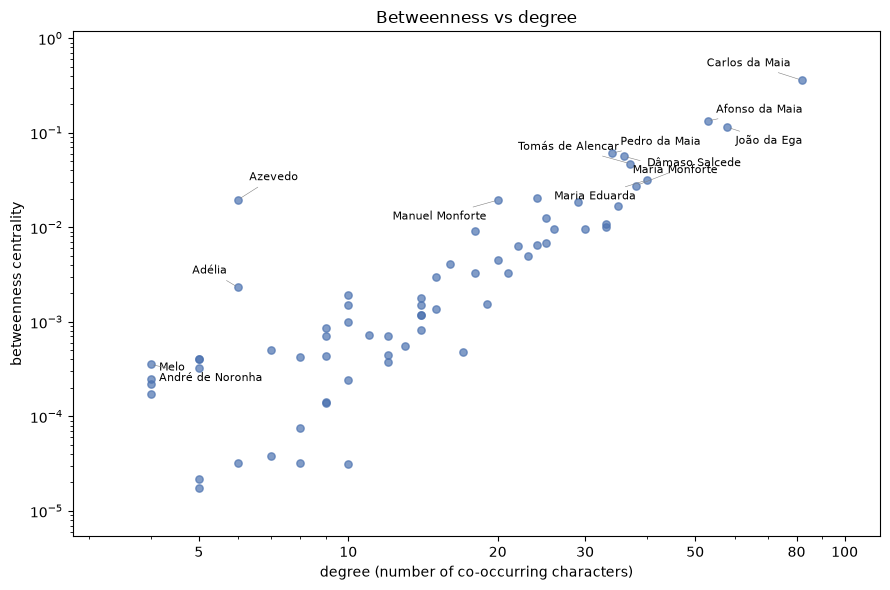

Highest betweenness for their degree (residual from the log-log trend)


,degree,betweenness,residual
character,,,
Azevedo,6,0.019608,2.018683
Adélia,6,0.002310,1.089772
André de Noronha,4,0.000355,0.740688
Manuel Monforte,20,0.019381,0.634780
Melo,4,0.000249,0.587594
Maria Eduarda Runa,5,0.000402,0.539392
Padre Vasques,5,0.000402,0.539392
Augusta,4,0.000218,0.529577
Pedro da Maia,34,0.060842,0.523917


In [15]:
plot_df = centrality[centrality["betweenness"] > 0].copy()
print(f"{(centrality['betweenness'] == 0).sum()} character(s) with betweenness 0 are not plotted.")

x, y = np.log10(plot_df["degree"]), np.log10(plot_df["betweenness"])
slope, intercept = np.polyfit(x, y, 1)
plot_df["residual"] = y - (slope * x + intercept)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(plot_df["degree"], plot_df["betweenness"], s=28, alpha=0.7, color="#4c72b0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.margins(x=0.12, y=0.12)
ax.set_xlabel("degree (number of co-occurring characters)")
ax.set_ylabel("betweenness centrality")
ax.set_title("Betweenness vs degree")

# plain numbers on the log x-axis instead of 4x10^0, 6x10^0, ...
lo, hi = plot_df["degree"].min(), plot_df["degree"].max()
ticks = [t for t in (1, 2, 3, 5, 10, 20, 30, 50, 80, 100, 150, 200) if lo * 0.8 <= t <= hi * 1.25]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# label the top characters by betweenness and by residual; stagger the labels so they overlap less
to_label = set(plot_df["betweenness"].nlargest(8).index) | set(plot_df["residual"].nlargest(5).index)
offsets = [(6, 6), (6, -12), (-8, 10), (8, 14), (-8, -14)]
for k, node in enumerate(sorted(to_label, key=lambda v: (plot_df.loc[v, "degree"], plot_df.loc[v, "betweenness"]))):
    dx, dy = offsets[k % len(offsets)]
    ax.annotate(plot_df.loc[node, "character"],
                (plot_df.loc[node, "degree"], plot_df.loc[node, "betweenness"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8,
                ha="left" if dx > 0 else "right",
                arrowprops=dict(arrowstyle="-", lw=0.4, color="gray"))
plt.tight_layout()
plt.show()

show(plot_df.nlargest(10, "residual").set_index("character")[["degree", "betweenness", "residual"]],
     {"degree": "{:.0f}", "betweenness": "{:.4f}", "residual": "{:+.2f}"},
     caption="Highest betweenness for their degree (residual from the log-log trend)")

## 9. Compared to what? (degree-preserving shuffle)

Week 3 insists that a centrality value only means something against a baseline. A hub has high betweenness in almost any network with this degree sequence, so a high value is not by itself a finding. Here the real betweenness of each character is compared with its value in networks where every character keeps its degree but the links are rewired at random. The $z$-score says how far the real value sits from that baseline; a large positive $z$ marks a character whose *position* gives more control than their *popularity* predicts. The shuffle works on the unweighted topology, so it tests the unweighted betweenness.

The test runs `N_SHUFFLES` shuffles and takes a few seconds to a minute. Treat large $|z|$ values as candidates to inspect, not as proof. With about a hundred characters, a few will cross any threshold by chance, and $z$ can become enormous for a low-degree character whose shuffled betweenness barely varies, so read the observed value and the shuffled mean next to it, not $z$ alone. The shuffle also destroys community structure, so in a network with strong communities many characters will differ from the baseline for that reason; use $z$ to rank candidates, not as a significance test.

In [16]:
def degree_preserving_copy(G, seed):
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from(G.edges())                 # topology only
    nswap = 10 * H.number_of_edges()
    nx.double_edge_swap(H, nswap=nswap, max_tries=nswap * 100, seed=seed)
    return H

node_order = list(G.nodes())
null = np.empty((N_SHUFFLES, len(node_order)))
for s in range(N_SHUFFLES):
    H = degree_preserving_copy(G, seed=SEED + s)
    b = nx.betweenness_centrality(H, normalized=True)
    null[s] = [b[v] for v in node_order]

obs  = centrality.loc[node_order, "betweenness"].to_numpy()
mu   = null.mean(axis=0)
sd   = null.std(axis=0, ddof=1)
z    = np.full(len(node_order), np.nan)
ok   = sd > 0
z[ok] = (obs[ok] - mu[ok]) / sd[ok]

null_table = pd.DataFrame({
    "character": [label(v) for v in node_order],
    "degree": centrality.loc[node_order, "degree"].to_numpy(),
    "betweenness": obs, "shuffled_mean": mu, "shuffled_std": sd, "z": z,
}, index=pd.Index(node_order, name="id")).sort_values("z", ascending=False, kind="mergesort")

fmt_null = {"degree": "{:.0f}", "betweenness": "{:.4f}", "shuffled_mean": "{:.4f}", "shuffled_std": "{:.4f}", "z": "{:+.1f}"}
show(null_table.head(15).set_index("character"), fmt_null, gradient=["z"],
     caption=f"Betweenness higher than degree predicts (top 15 by z, {N_SHUFFLES} shuffles)")
show(null_table.dropna(subset=["z"]).tail(10).set_index("character"), fmt_null,
     caption="Betweenness lower than degree predicts (bottom 10 by z)")
print(f"|z| > 2 for {(null_table['z'].abs() > 2).sum()} of {len(null_table)} characters.")

Betweenness higher than degree predicts (top 15 by z, 200 shuffles)


,degree,betweenness,shuffled_mean,shuffled_std,z
character,,,,,
Azevedo,6,0.019608,0.000476,0.001478,12.942514
Pedro da Maia,34,0.060842,0.028589,0.009327,3.457936
Afonso da Maia,53,0.133015,0.091399,0.013378,3.110869
Maria Monforte,36,0.056151,0.031315,0.008492,2.924709
Manuel Monforte,20,0.019381,0.007265,0.004664,2.597577
Carlos da Maia,82,0.359385,0.323370,0.014179,2.539998
Vilaça,24,0.020589,0.011964,0.006442,1.338915
Adélia,6,0.002310,0.000412,0.001436,1.321348
Tomás de Alencar,37,0.046999,0.035728,0.010611,1.062208


Betweenness lower than degree predicts (bottom 10 by z)


,degree,betweenness,shuffled_mean,shuffled_std,z
character,,,,,
Steinbroken,25,0.006892,0.013348,0.006655,-0.970081
Teles da Gama,21,0.003297,0.008032,0.004723,-1.002464
D. Maria da Cunha,17,0.000485,0.005291,0.004728,-1.016447
Dâmaso Salcede,38,0.027590,0.039020,0.011087,-1.030922
Maria Eduarda,40,0.031667,0.045307,0.011166,-1.221604
D. Diogo Coutinho,19,0.001557,0.006327,0.003749,-1.272345
Taveira,30,0.009634,0.020129,0.007678,-1.366843
Vilaça Júnior,35,0.017001,0.031161,0.009379,-1.509722
Craft,33,0.010143,0.025002,0.007959,-1.867062


|z| > 2 for 6 of 103 characters.


## 10. Save the results

In [17]:
export = pd.concat([centrality, ranks], axis=1)
export["betweenness_z"] = null_table["z"].reindex(export.index)
export.sort_values("degree", ascending=False, kind="mergesort").to_csv(OUTPUT_FILE, encoding="utf-8")
print(f"Saved {len(export)} rows to {OUTPUT_FILE}")

Saved 103 rows to Data\os_maias_centralities.csv
